# Exploring and cleaning the book data

Download the book metadata, check missing values, and save the rows used by the other notebooks. Run this notebook from the repository root. The download uses KaggleHub.


In [1]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

path = Path(kagglehub.dataset_download("dylanjcastillo/7k-books-with-metadata"))
books = pd.read_csv(path / "books.csv")
books.head()

c:\Python Projects\Book-Recommender\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count
0,9780002005883,0002005883,Gilead,NaN,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0
1,9780002261982,0002261987,Spider's Web,A Novel,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0
2,9780006163831,0006163831,The One Tree,NaN,Stephen R. Donaldson,American fiction,http://books.google.com/books/content?id=OmQaw...,Volume Two of Stephen Donaldson's acclaimed se...,1982.0,3.97,479.0,172.0
3,9780006178736,0006178731,Rage of angels,NaN,Sidney Sheldon,Fiction,http://books.google.com/books/content?id=FKo2T...,"A memorable, mesmerizing heroine Jennifer -- b...",1993.0,3.93,512.0,29532.0
4,9780006280897,0006280897,The Four Loves,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=XhQ5X...,Lewis' work on the nature of love divides love...,2002.0,4.15,170.0,33684.0


## Check missing values


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6810 entries, 0 to 6809
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   isbn13          6810 non-null   int64  
 1   isbn10          6810 non-null   object 
 2   title           6810 non-null   object 
 3   subtitle        2381 non-null   object 
 4   authors         6738 non-null   object 
 5   categories      6711 non-null   object 
 6   thumbnail       6481 non-null   object 
 7   description     6548 non-null   object 
 8   published_year  6804 non-null   float64
 9   average_rating  6767 non-null   float64
 10  num_pages       6767 non-null   float64
 11  ratings_count   6767 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 638.6+ KB


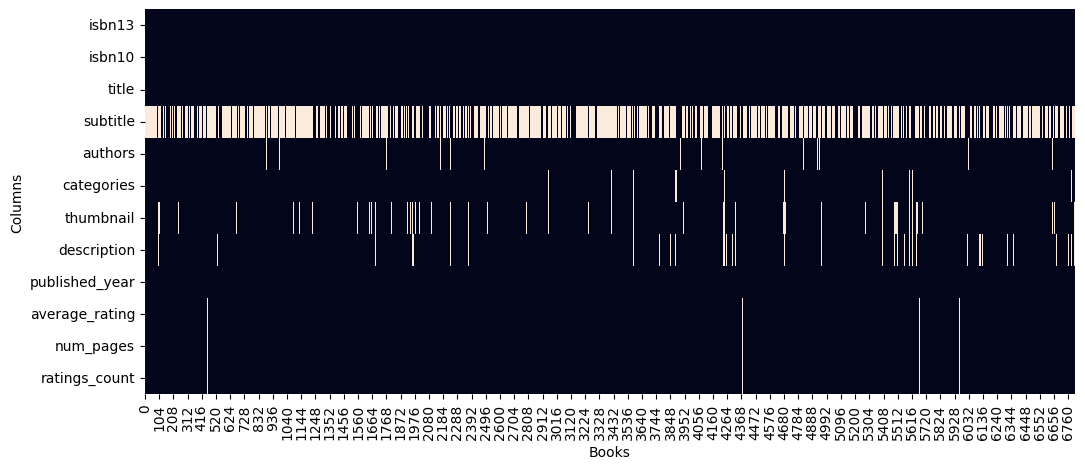

In [2]:
books.info()

plt.figure(figsize=(12, 5))
sns.heatmap(books.isna().transpose(), cbar=False)
plt.xlabel("Books")
plt.ylabel("Columns")
plt.show()

## Look at the numeric columns

Use 2024 as the reference year to keep the original analysis consistent.


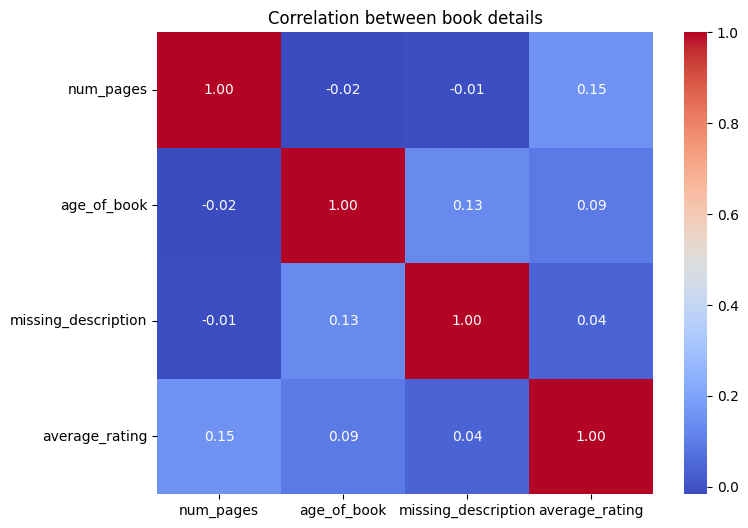

In [3]:
books["missing_description"] = books["description"].isna().astype(int)
books["age_of_book"] = 2024 - books["published_year"]

columns = ["num_pages", "age_of_book", "missing_description", "average_rating"]
correlations = books[columns].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between book details")
plt.show()

## Keep books with enough information

Remove missing descriptions, page counts, ratings, and publication years. Keep descriptions with at least 25 words, as in the original notebook.


In [4]:
required_columns = ["description", "num_pages", "average_rating", "published_year"]
clean_books = books.dropna(subset=required_columns).copy()
clean_books["words_in_description"] = clean_books["description"].str.split().str.len()

clean_books["words_in_description"].describe()

count    6507.000000
mean       66.325803
std        66.120291
min         1.000000
25%        27.000000
50%        40.000000
75%        82.000000
max       920.000000
Name: words_in_description, dtype: float64

In [5]:
clean_books = clean_books.loc[clean_books["words_in_description"] >= 25].copy()
clean_books["categories"].value_counts().head(15)

categories
Fiction                      2111
Juvenile Fiction              390
Biography & Autobiography     311
History                       207
Literary Criticism            124
Philosophy                    117
Religion                      117
Comics & Graphic Novels       116
Drama                          86
Juvenile Nonfiction            57
Science                        56
Poetry                         51
Literary Collections           50
Business & Economics           49
Social Science                 48
Name: count, dtype: int64

## Add display titles and tagged descriptions


In [6]:
clean_books["title_and_subtitle"] = clean_books["title"]
has_subtitle = clean_books["subtitle"].notna()
clean_books.loc[has_subtitle, "title_and_subtitle"] = (
    clean_books.loc[has_subtitle, "title"]
    + ": "
    + clean_books.loc[has_subtitle, "subtitle"]
)

# The ISBN lets us match a search result back to its book.
clean_books["tagged_description"] = (
    clean_books["isbn13"].astype(str) + " " + clean_books["description"]
)
clean_books[["title_and_subtitle", "tagged_description"]].head()

,title_and_subtitle,tagged_description
0,Gilead,9780002005883 A NOVEL THAT READERS and critics...
1,Spider's Web: A Novel,9780002261982 A new 'Christie for Christmas' -...
3,Rage of angels,"9780006178736 A memorable, mesmerizing heroine..."
4,The Four Loves,9780006280897 Lewis' work on the nature of lov...
5,The Problem of Pain,"9780006280934 ""In The Problem of Pain, C.S. Le..."


## Save the cleaned data


In [7]:
temporary_columns = [
    "subtitle",
    "missing_description",
    "age_of_book",
    "words_in_description",
]
clean_books = clean_books.drop(columns=temporary_columns)
clean_books.to_csv("books_cleaned.csv", index=False)
print(f"Saved {len(clean_books)} books to books_cleaned.csv")

Saved 5197 books to books_cleaned.csv
